# Laboratorio Semana 1 — ¿Cuánto vale cada cliente, y qué tan seguro estás de esa cifra?


(2,000 clientes, 18 meses de transacciones). Se construye en cuatro bloques, de lo más simple a lo más fino:

| Bloque | Qué hacemos | Tiempo |
|---|---|---|
| **A. RFM** | Tres números por cliente → segmentos con nombre | ~15 min |
| **B. CLV (fórmula)** | Convertir comportamiento en dinero | ~15 min |
| **C. BG/NBD + Gamma-Gamma** | Agregar incertidumbre: ¿sigue vivo? ¿cuánto comprará? | ~25 min |
| **D. Cierre** | Comparar los tres escalones y el puente a Churn/Uplift | ~5 min |

```
CLV = (ARPU × margen) × r / (1 + d − r) − CAC
```


In [1]:
# En Google Colab, descomenten la siguiente línea:
# !pip install lifetimes

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
VERDE, OSCURO, NARANJA, GRIS = "#00704A", "#11241C", "#C4512F", "#9A988E"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

In [2]:
transactions = pd.read_csv("data/transactions.csv", parse_dates=["transaction_date"])
customers = pd.read_csv("data/customers.csv", parse_dates=["signup_date", "last_active_date"])

FECHA_CORTE = transactions["transaction_date"].max()
print(f"{len(customers):,} clientes · {len(transactions):,} transacciones")
print(f"De {transactions['transaction_date'].min().date()} a {FECHA_CORTE.date()}  (fecha de corte = {FECHA_CORTE.date()})")
transactions.head()

2,000 clientes · 164,239 transacciones
De 2024-09-02 a 2026-08-30  (fecha de corte = 2026-08-30)


,transaction_id,customer_id,transaction_date,amount
0,1,1,2025-02-11,16.00
1,16,2,2025-10-15,9.13
2,5,2,2025-10-29,9.08
3,12,2,2025-11-06,9.48
4,15,2,2025-11-07,2.80


---
# Bloque A y B — RFM: tres números por cliente

- **R**ecency: días desde la última compra (**menos es mejor**).
- **F**requency: cuántas compras hizo.
- **M**onetary: cuánto gastó en total.

**Pregunta al grupo:** antes de correr nada, ¿qué cliente es mejor, uno con R = 5 días o uno con R = 200 días?

In [3]:
rfm = transactions.groupby("customer_id").agg(
    recency=("transaction_date", lambda s: (FECHA_CORTE - s.max()).days),
    frequency=("transaction_date", "count"),
    monetary=("amount", "sum"),
).reset_index()

rfm.describe().round(1)

,customer_id,recency,frequency,monetary
count,2000.0,2000.0,2000.0,2000.0
mean,1000.5,172.3,82.1,667.8
std,577.5,198.2,111.3,849.5
min,1.0,0.0,1.0,2.5
25%,500.8,2.0,10.0,95.8
50%,1000.5,85.5,39.0,352.3
75%,1500.2,320.0,107.0,911.7
max,2000.0,707.0,865.0,6528.4


### De número a puntaje (1–5) con quintiles

Ojo con **la trampa de la Recency invertida**: en R el puntaje alto debe ir a quien compró **hace menos días**.

In [4]:
# rank(method="first") evita empates en los cortes
rfm["R"] = pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)   # invertido
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm.sort_values("monetary", ascending=False).head(5)

,customer_id,recency,frequency,monetary,R,F,M
49,50,2,865,6528.40,4,5,5
522,523,2,793,5966.92,4,5,5
767,768,0,604,5521.52,5,5,5
1653,1654,75,755,5425.98,3,5,5
347,348,1,714,5284.82,5,5,5


### Del puntaje al segmento con nombre

Un número no se le manda a marketing; un nombre sí. Reglas legibles (los cortes son quintiles de **esta** base):

In [5]:
def segmento(row):
    R, F, M = row["R"], row["F"], row["M"]
    if R >= 4 and F >= 4 and M >= 4:
        return "Champions"
    if R <= 2 and F >= 4 and M >= 4:
        return "At Risk"
    if R >= 3 and F >= 4:
        return "Loyal Customers"
    if R >= 4 and F <= 3:
        return "Potential Loyalist"
    if R <= 2 and F <= 2 and M <= 2:
        return "Lost" if R == 1 else "Hibernating"
    return "Otros"

rfm["segmento"] = rfm.apply(segmento, axis=1)

tabla_seg = rfm.groupby("segmento").agg(
    clientes=("customer_id", "count"),
    recencia_prom=("recency", "mean"),
    frecuencia_prom=("frequency", "mean"),
    gasto_prom=("monetary", "mean"),
    gasto_total=("monetary", "sum"),
)
tabla_seg["% clientes"] = (tabla_seg["clientes"] / tabla_seg["clientes"].sum() * 100).round(1)
tabla_seg["% del gasto"] = (tabla_seg["gasto_total"] / tabla_seg["gasto_total"].sum() * 100).round(1)
orden = ["Champions", "Loyal Customers", "Potential Loyalist", "At Risk", "Hibernating", "Lost", "Otros"]
tabla_seg = tabla_seg.reindex([s for s in orden if s in tabla_seg.index])
tabla_seg.drop(columns="gasto_total").round(1)

,clientes,recencia_prom,frecuencia_prom,gasto_prom,% clientes,% del gasto
segmento,,,,,,
Champions,494,1.9,195.9,1545.9,24.7,57.2
Loyal Customers,154,81.8,168.7,1346.3,7.7,15.5
Potential Loyalist,290,3.6,26.9,242.0,14.5,5.3
At Risk,138,304.8,131.7,1083.5,6.9,11.2
Hibernating,191,266.2,8.2,78.3,9.6,1.1
Lost,276,516.9,6.6,63.5,13.8,1.3
Otros,457,206.7,26.5,246.1,22.8,8.4


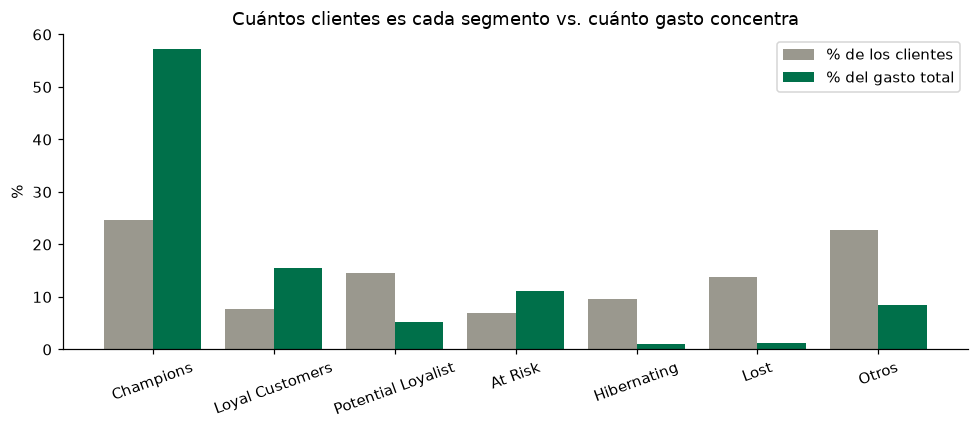

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(tabla_seg))
ax.bar(x - 0.2, tabla_seg["% clientes"], 0.4, label="% de los clientes", color=GRIS)
ax.bar(x + 0.2, tabla_seg["% del gasto"], 0.4, label="% del gasto total", color=VERDE)
ax.set_xticks(x)
ax.set_xticklabels(tabla_seg.index, rotation=20)
ax.set_ylabel("%")
ax.set_title("Cuántos clientes es cada segmento vs. cuánto gasto concentra")
ax.legend()
plt.tight_layout()
plt.savefig("rfm_segmentos.png", dpi=150)
plt.show()

En el segmento **At Risk**. ¿Por qué duele más perderlo que perder a un *Hibernating*?

---
# Bloque C — BG/NBD: ¿sigue vivo, y cuánto comprará?

**El problema:** en un negocio *no contractual* nadie cancela un café. Un cliente con 90 días sin venir,
¿está **dormido** o **se fue para siempre**? RFM no puede responderlo; BG/NBD sí, con una probabilidad.

### Paso 1 — separar el tiempo en dos ventanas
Entrenamos con el pasado y **escondemos los últimos 90 días** para comprobar si el modelo acierta.

In [7]:
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data
from lifetimes.plotting import plot_probability_alive_matrix

CORTE_CAL = FECHA_CORTE - pd.Timedelta(days=90)
calibracion = transactions[transactions["transaction_date"] <= CORTE_CAL]
holdout = transactions[transactions["transaction_date"] > CORTE_CAL]

print(f"Calibración: hasta {CORTE_CAL.date()}  ({len(calibracion):,} transacciones)")
print(f"Holdout (oculto al modelo): {len(holdout):,} transacciones en los últimos 90 días")

Calibración: hasta 2026-06-01  (132,600 transacciones)
Holdout (oculto al modelo): 31,639 transacciones en los últimos 90 días


### Paso 2 — las tres letras del modelo: `x`, `t_x`, `T`
- **x** = compras **repetidas** (sin contar la primera).
- **t_x** = días entre la **primera** y la **última** compra.
- **T** = días entre la **primera** compra y el final de la calibración.

**No confundir con RFM:** la Recency de RFM mira hacia *hoy*; `t_x` mira hacia *atrás*, dentro de la ventana.
El equivalente real de la Recency es **T − t_x** (días sin comprar vistos desde el final de la calibración).

In [8]:
resumen = summary_data_from_transaction_data(
    calibracion, "customer_id", "transaction_date",
    monetary_value_col="amount", observation_period_end=CORTE_CAL, freq="D",
)
resumen = resumen.rename(columns={"frequency": "x", "recency": "t_x"})
resumen["dias_sin_comprar"] = resumen["T"] - resumen["t_x"]

print(f"Clientes establecidos (con al menos 1 compra en la calibración): {len(resumen):,}")
print(f"Compradores de una sola vez (x = 0): {(resumen['x'] == 0).sum()}  ({(resumen['x'] == 0).mean():.1%})")
resumen.head()

Clientes establecidos (con al menos 1 compra en la calibración): 1,809
Compradores de una sola vez (x = 0): 122  (6.7%)


,x,t_x,T,monetary_value,dias_sin_comprar
customer_id,,,,,
1,0.0,0.0,475.0,0.000000,475.0
2,20.0,117.0,229.0,7.621000,112.0
3,2.0,49.0,54.0,11.185000,5.0
4,49.0,401.0,401.0,11.982653,0.0
5,192.0,473.0,473.0,9.723542,0.0


### Paso 3 — ajustar el modelo BG/NBD

In [9]:
bgf = BetaGeoFitter(penalizer_coef=0.001)
bgf.fit(resumen["x"], resumen["t_x"], resumen["T"])
bgf.summary.round(3)

,coef,se(coef),lower 95% bound,upper 95% bound
r,1.238,0.044,1.152,1.324
alpha,4.749,0.197,4.363,5.135
a,0.227,0.010,0.206,0.247
b,4.514,0.317,3.893,5.135


Lectura sencilla de los cuatro parámetros (se estiman con **toda** la base):
- **r, α** → qué tan distintos compran los clientes *mientras están vivos* (Poisson-Gamma).
- **a, b** → qué tan probable es que un cliente "muera" después de cada compra (Beta-Geométrica).

### Paso 4 — P(vivo): la probabilidad que RFM no tiene

In [10]:
resumen["P_vivo"] = bgf.conditional_probability_alive(resumen["x"], resumen["t_x"], resumen["T"])
real_n = holdout.groupby("customer_id").size()
resumen["compras_holdout"] = real_n.reindex(resumen.index).fillna(0).astype(int)
print(f"el numero promedio de compras holdout es ",resumen["compras_holdout"].mean())
# Clientes con ~90 días sin comprar: ¿dormidos o perdidos?
mismo_ausente = resumen[resumen["dias_sin_comprar"].between(10, 30) & (resumen["x"] >= 1)].sort_values("x")
ejemplos = pd.concat([mismo_ausente.head(2), mismo_ausente.tail(2)])
ejemplos[["x", "t_x", "T", "dias_sin_comprar", "P_vivo", "compras_holdout"]].round(2)

el numero promedio de compras holdout es  15.626865671641792


,x,t_x,T,dias_sin_comprar,P_vivo,compras_holdout
customer_id,,,,,,
565,1.0,9.0,25.0,16.0,0.78,11
321,1.0,27.0,44.0,17.0,0.88,2
1860,212.0,580.0,590.0,10.0,0.96,45
481,281.0,545.0,560.0,15.0,0.39,0


**Lo importante:** los cuatro llevan **≈ 15 días sin comprar** (misma Recency de RFM), pero **no tienen la misma P(vivo)**.
Quien compraba muy seguido y de pronto se calló tiene P(vivo) baja; quien compraba poco, alta.
La última columna muestra qué pasó de verdad en los 90 días ocultos.

¿a cuál le mandarían una campaña de reactivación? ¿Y qué pasa con los de `x = 0`?

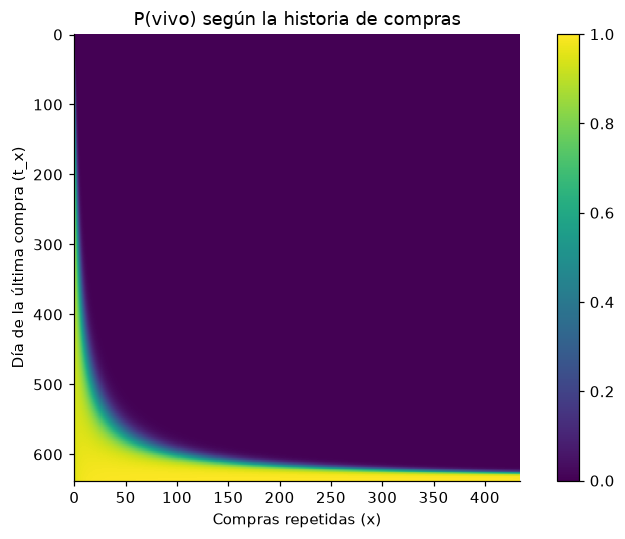

In [11]:
plt.figure(figsize=(7, 5))
plot_probability_alive_matrix(bgf, title="P(vivo) según la historia de compras",
                              xlabel="Compras repetidas (x)",
                              ylabel="Día de la última compra (t_x)")   # abajo = compró hace poco
plt.tight_layout()
plt.savefig("matriz_p_vivo.png", dpi=150)
plt.show()

**Cómo leer el mapa:** eje horizontal = compras repetidas (*x*); eje vertical = el día de la última compra (*t_x*),
donde **abajo = compró hace poco** (cerca del final de la ventana).
Zona **amarilla** = muy probablemente **vivo**; zona **morada** = probablemente **se fue**.

Fíjense en dos cosas: (1) quien compró mucho pero **no ha vuelto** (arriba a la derecha) cae en morado:
si compraba tanto y se calló, es raro que siga vivo; (2) la frontera es muy nítida porque estos datos
son sintéticos: en la vida real la zona gris es más ancha.

### Paso 5 — ¿acierta? Predicción de compras en los 90 días ocultos

In [12]:
resumen["pred_compras_90d"] = bgf.conditional_expected_number_of_purchases_up_to_time(
    90, resumen["x"], resumen["t_x"], resumen["T"])

corr_compras = resumen[["pred_compras_90d", "compras_holdout"]].corr().iloc[0, 1]
print(f"Correlación predicho vs. real (compras en 90 días): {corr_compras:.3f}")
print(f"Compras totales predichas: {resumen['pred_compras_90d'].sum():,.0f}   ·   reales: {resumen['compras_holdout'].sum():,.0f}")

Correlación predicho vs. real (compras en 90 días): 0.908
Compras totales predichas: 23,000   ·   reales: 28,269


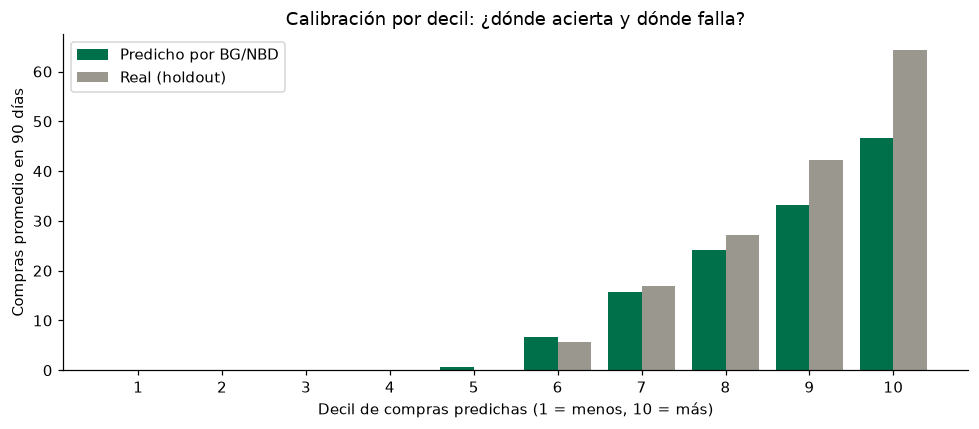

,predicho,real
decil,,
1,0.00,0.00
2,0.00,0.00
3,0.00,0.00
4,0.02,0.04
5,0.61,0.10
6,6.61,5.68
7,15.73,16.82
8,24.25,27.10
9,33.20,42.17


In [13]:
resumen["decil"] = pd.qcut(resumen["pred_compras_90d"].rank(method="first"), 10, labels=range(1, 11))
calib = resumen.groupby("decil").agg(predicho=("pred_compras_90d", "mean"), real=("compras_holdout", "mean"))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(10)
ax.bar(x - 0.2, calib["predicho"], 0.4, label="Predicho por BG/NBD", color=VERDE)
ax.bar(x + 0.2, calib["real"], 0.4, label="Real (holdout)", color=GRIS)
ax.set_xticks(x)
ax.set_xticklabels(range(1, 11))
ax.set_xlabel("Decil de compras predichas (1 = menos, 10 = más)")
ax.set_ylabel("Compras promedio en 90 días")
ax.set_title("Calibración por decil: ¿dónde acierta y dónde falla?")
ax.legend()
plt.tight_layout()
plt.savefig("calibracion_deciles.png", dpi=150)
plt.show()
calib.round(2)

**Lectura:** la relación es **monótona** (más decil predicho → más compras reales), señal de modelo sano. Y además:

- Los deciles **1 a 4 son ≈ 0 compras**: son clientes que ya se fueron, y el modelo lo sabe (el decil 5 predice 0.6 y compra 0.1).
- Donde **más falla es en el decil 10**: predice ≈ 47 compras y los clientes reales hicieron ≈ 64
  (los más activos compran **más** de lo que el modelo espera). Por eso el total predicho (23,000) queda por debajo del real (28,269).

¿qué decisión de negocio sería peligrosa si nos fiamos del modelo solo en el decil 10?

### Paso 6 — Gamma-Gamma: cuánto vale cada compra
BG/NBD predice **cuántas** compras. Gamma-Gamma predice **cuánto gasta** en cada una.
Supuesto clave: que el monto por compra **no dependa de la frecuencia**. Se revisa antes de usarlo:

In [14]:
repetidores = resumen[resumen["x"] > 0]
corr_fm = repetidores[["x", "monetary_value"]].corr().iloc[0, 1]
print(f"Correlación entre frecuencia y monto por compra: {corr_fm:.3f}   (cerca de 0 = el supuesto aguanta)")

gg = GammaGammaFitter(penalizer_coef=0.001)
gg.fit(repetidores["x"], repetidores["monetary_value"])

resumen["gasto_por_compra"] = repetidores["monetary_value"].mean()          # compradores de una vez: promedio de la base
resumen.loc[repetidores.index, "gasto_por_compra"] = gg.conditional_expected_average_profit(
    repetidores["x"], repetidores["monetary_value"])

resumen["gasto_pred_90d"] = resumen["pred_compras_90d"] * resumen["gasto_por_compra"]
gasto_real = holdout.groupby("customer_id")["amount"].sum()
resumen["gasto_real_90d"] = gasto_real.reindex(resumen.index).fillna(0)

Correlación entre frecuencia y monto por compra: 0.003   (cerca de 0 = el supuesto aguanta)


### Paso 7 — la comparación que importa: fórmula simple vs. BG/NBD + Gamma-Gamma
La "fórmula simple" extrapola el **ritmo pasado de gasto** a los próximos 90 días (supone que el cliente sigue vivo).
Las dos se comparan contra lo que los clientes **realmente** gastaron en los 90 días ocultos.

In [15]:
gasto_hist = calibracion.groupby("customer_id")["amount"].sum()
resumen["gasto_simple_90d"] = (gasto_hist.reindex(resumen.index) / resumen["T"].clip(lower=1)) * 90

comparacion = pd.DataFrame({
    "Modelo": ["Fórmula simple (ritmo pasado × 90 días)", "BG/NBD + Gamma-Gamma"],
    "Correlación con el gasto real": [
        resumen[["gasto_simple_90d", "gasto_real_90d"]].corr().iloc[0, 1],
        resumen[["gasto_pred_90d", "gasto_real_90d"]].corr().iloc[0, 1],
    ],
    "Gasto total predicho ($)": [resumen["gasto_simple_90d"].sum(), resumen["gasto_pred_90d"].sum()],
    "Gasto total real ($)": [resumen["gasto_real_90d"].sum()] * 2,
})
comparacion.round(3)

,Modelo,Correlación con el gasto real,Gasto total predicho ($),Gasto total real ($)
0,Fórmula simple (ritmo pasado × 90 días),0.801,351131.197,227670.3
1,BG/NBD + Gamma-Gamma,0.907,242381.827,227670.3


**Dos cosas que mirar:** (1) la **correlación** (¿ordena bien a los clientes?) y
(2) el **total** (¿acierta cuánto dinero entra?). La fórmula simple suele *pasarse* en el total porque
cuenta como activos a clientes que ya se fueron.

---
# Bloque D — Cierre: los tres escalones lado a lado

Ahora reunimos RFM, la fórmula de CLV y BG/NBD en una sola tabla, mirando **hacia adelante**
(se vuelve a ajustar con toda la base, hasta la fecha de corte).

In [16]:
MARGEN=0.7
completo = summary_data_from_transaction_data(
    transactions, "customer_id", "transaction_date", monetary_value_col="amount",
    observation_period_end=FECHA_CORTE, freq="D")

bgf_full = BetaGeoFitter(penalizer_coef=0.001).fit(completo["frequency"], completo["recency"], completo["T"])

rep_full = completo[completo["frequency"] > 0]
gg_full = GammaGammaFitter(penalizer_coef=0.001).fit(rep_full["frequency"], rep_full["monetary_value"])

completo["gasto_por_compra"] = rep_full["monetary_value"].mean()
completo.loc[rep_full.index, "gasto_por_compra"] = gg_full.conditional_expected_average_profit(
    rep_full["frequency"], rep_full["monetary_value"])

completo["P_vivo"] = bgf_full.conditional_probability_alive(completo["frequency"], completo["recency"], completo["T"])

# CLV probabilístico a 12 meses (con margen), sin restar CAC todavía
completo["valor_12m"] = bgf_full.conditional_expected_number_of_purchases_up_to_time(
    365, completo["frequency"], completo["recency"], completo["T"]) * completo["gasto_por_compra"] * MARGEN

In [17]:
MARGEN = 0.70
D=0.01

transactions["month"] = transactions["transaction_date"].dt.to_period("M")
activos = transactions.groupby("month")["customer_id"].apply(set).sort_index()
meses = activos.index.tolist()

retencion = [len(activos[meses[i]] & activos[meses[i + 1]]) / len(activos[meses[i]])
             for i in range(len(meses) - 1)]
r_mensual = float(np.mean(retencion[-12:]))
print(f"Retención mensual promedio (últimos 12 meses): r = {r_mensual:.1%}")

mult = r_mensual / (1 + D - r_mensual)

clv = rfm.merge(customers[["customer_id", "signup_date", "acquisition_cost", "segment"]], on="customer_id")
clv["meses_cliente"] = ((FECHA_CORTE - clv["signup_date"]).dt.days / 30.44).clip(lower=1)
clv["arpu_mensual"] = clv["monetary"] / clv["meses_cliente"]
clv["clv_formula"] = clv["arpu_mensual"] * MARGEN * mult - clv["acquisition_cost"]

print(f"ARPU mensual promedio: ${clv['arpu_mensual'].mean():.2f}   ·   CAC promedio: ${clv['acquisition_cost'].mean():.2f}")
print(f"CLV promedio (fórmula): ${clv['clv_formula'].mean():,.2f}")
print(f"Clientes con CLV NEGATIVO (nunca recuperan el CAC): {(clv['clv_formula'] < 0).mean():.1%}")

Retención mensual promedio (últimos 12 meses): r = 90.6%
ARPU mensual promedio: $58.89   ·   CAC promedio: $13.59
CLV promedio (fórmula): $347.43
Clientes con CLV NEGATIVO (nunca recuperan el CAC): 10.7%


In [18]:
final = clv.merge(completo[["P_vivo", "valor_12m"]], left_on="customer_id", right_index=True)
final["clv_prob_12m"] = final["valor_12m"] - final["acquisition_cost"]

resumen_final = final.groupby("segmento").agg(
    clientes=("customer_id", "count"),
    CLV_formula_prom=("clv_formula", "mean"),
    P_vivo_prom=("P_vivo", "mean"),
    CLV_prob_12m_prom=("clv_prob_12m", "mean"),
)
resumen_final = resumen_final.reindex([s for s in orden if s in resumen_final.index])
resumen_final.round(2)

,clientes,CLV_formula_prom,P_vivo_prom,CLV_prob_12m_prom
segmento,,,,
Champions,494,770.57,0.99,928.83
Loyal Customers,154,562.87,0.15,82.59
Potential Loyalist,290,402.04,0.97,430.51
At Risk,138,337.74,0.00,-12.54
Hibernating,191,25.96,0.22,-12.22
Lost,276,5.90,0.21,-13.73
Otros,457,126.31,0.22,11.47


In [19]:
# El "CLV zombi": la fórmula dice que valen, BG/NBD dice que ya se fueron
zombis = final[(final["clv_formula"] > 0) & (final["P_vivo"] < 0.20)]
valor_zombi = zombis["clv_formula"].sum() / final.loc[final["clv_formula"] > 0, "clv_formula"].sum()

print(f"Clientes con CLV (fórmula) positivo pero P(vivo) < 20%: {len(zombis)}  ({len(zombis) / len(final):.1%} de la base)")
print(f"Esa gente aporta {valor_zombi:.1%} del CLV positivo que reporta la fórmula.")
print()

# ¿Qué dice P(vivo) del segmento At Risk de RFM?
ar = final[final["segmento"] == "At Risk"]
print(f"At Risk (RFM): {len(ar)} clientes · P(vivo) promedio = {ar['P_vivo'].mean():.2f} · con P(vivo) > 50%: {(ar['P_vivo'] > 0.5).sum()}")
print("RFM dice 'reactivación urgente'; BG/NBD dice que la mayoría ya se fue.")
print()

# La zona gris: ni claramente vivos ni claramente perdidos, y con valor alto → ahí SÍ hay algo que decidir
gris = final[final["P_vivo"].between(0.30, 0.90) & (final["clv_formula"] > final["clv_formula"].median())]
print(f"Zona gris (0.30 ≤ P(vivo) ≤ 0.90, CLV por encima de la mediana): {len(gris)} clientes")
print(gris[["recency", "frequency", "P_vivo", "clv_formula"]].describe().loc[["mean", "min", "max"]].round(2))

Clientes con CLV (fórmula) positivo pero P(vivo) < 20%: 860  (43.0% de la base)
Esa gente aporta 25.6% del CLV positivo que reporta la fórmula.

At Risk (RFM): 138 clientes · P(vivo) promedio = 0.00 · con P(vivo) > 50%: 0
RFM dice 'reactivación urgente'; BG/NBD dice que la mayoría ya se fue.

Zona gris (0.30 ≤ P(vivo) ≤ 0.90, CLV por encima de la mediana): 21 clientes
      recency  frequency  P_vivo  clv_formula
mean    17.57      41.52    0.74       357.34
min     10.00       7.00    0.41       239.91
max     28.00     205.00    0.89       830.04


## Conclusiones

1. **RFM** describe: rápido, barato, sin modelo. Pero un número no es una decisión.
2. **CLV (fórmula)** pone el dinero: un número financiero… que supone que el cliente **nunca se va**.
3. **BG/NBD + Gamma-Gamma** agrega incertidumbre: una **probabilidad de seguir vivo** y compras futuras esperadas.


Relación con Churn y Uplift:

1. **RFM dice "At Risk: reactivación urgente", pero BG/NBD dice que esos clientes ya se fueron** (P(vivo) ≈ 0).
   Reactivar cuesta más que prevenir: el momento de actuar era *antes*, cuando todavía estaban vivos.
2. **El 43% de la base sigue sumando CLV en la fórmula aunque su P(vivo) es menor a 20%.** Un CLV inflado
   lleva a invertir en quien ya no está.

> Saber que alguien **probablemente se va** no es lo mismo que saber **a quién conviene contactar**.

De eso se trata Churn y Uplift: ¿el cupón de verdad *cambia* la decisión de ese cliente, o se lo estamos
regalando a alguien que de todos modos volvía?
